In [1]:
print("ready")


ready


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

# Task 1: Dataset Understanding and Inspection

In [3]:
df = pd.read_csv("powerconsumption.csv")

In [4]:
print(df.shape)

(52416, 9)


In [5]:
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  str    
 1   Temperature             52416 non-null  float64
 2   Humidity                52416 non-null  float64
 3   WindSpeed               52416 non-null  float64
 4   GeneralDiffuseFlows     52416 non-null  float64
 5   DiffuseFlows            52416 non-null  float64
 6   PowerConsumption_Zone1  52416 non-null  float64
 7   PowerConsumption_Zone2  52416 non-null  float64
 8   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(8), str(1)
memory usage: 3.6 MB


In [7]:
print("Missing values per column:")
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
Datetime                  0
Temperature               0
Humidity                  0
WindSpeed                 0
GeneralDiffuseFlows       0
DiffuseFlows              0
PowerConsumption_Zone1    0
PowerConsumption_Zone2    0
PowerConsumption_Zone3    0
dtype: int64
Duplicate rows: 0


In [8]:
dd = pd.read_csv("powerconsumption_datadictionary.csv")
dd

,Field,Description
0,Datetime,The date and time of the recording
1,Temperature,The Temperature in Celsius
2,Humidity,The concentration of water vapor in the air
3,WindSpeed,The speed of the wind in kilometers per hour
4,GeneralDiffuseFlows,The measurement of how much emissions gases di...
5,DiffuseFlows,The measurement of how much emissions gases di...
6,PowerConsumption_Zone1,The power consumption in Kilowatt-Hours in Pow...
7,PowerConsumption_Zone2,The power consumption in Kilowatt-Hours in Pow...
8,PowerConsumption_Zone3,The power consumption in Kilowatt-Hours in Pow...


In [9]:
df["Datetime"] = pd.to_datetime(df["Datetime"], format="%m/%d/%Y %H:%M")
print("Start:", df["Datetime"].min())
print("End:  ", df["Datetime"].max())
print("Duplicate timestamps:", df["Datetime"].duplicated().sum())
print("In chronological order:", df["Datetime"].is_monotonic_increasing)

Start: 2017-01-01 00:00:00
End:   2017-12-30 23:50:00
Duplicate timestamps: 0
In chronological order: True


In [10]:
print(df["Datetime"].diff().value_counts())

Datetime
0 days 00:10:00    52415
Name: count, dtype: int64


In [11]:
pd.set_option("display.max_colwidth", None)
dd

,Field,Description
0,Datetime,The date and time of the recording
1,Temperature,The Temperature in Celsius
2,Humidity,The concentration of water vapor in the air
3,WindSpeed,The speed of the wind in kilometers per hour
4,GeneralDiffuseFlows,The measurement of how much emissions gases diffuse into the broader atmosphere
5,DiffuseFlows,The measurement of how much emissions gases diffuse into the local atmosphere
6,PowerConsumption_Zone1,The power consumption in Kilowatt-Hours in Power Zone 1
7,PowerConsumption_Zone2,The power consumption in Kilowatt-Hours in Power Zone 2
8,PowerConsumption_Zone3,The power consumption in Kilowatt-Hours in Power Zone 3


In [12]:
df["Hour"] = df["Datetime"].dt.hour
df.groupby("Hour")[["GeneralDiffuseFlows", "DiffuseFlows", "Temperature"]].mean().round(1)

,GeneralDiffuseFlows,DiffuseFlows,Temperature
Hour,,,
0,0.1,0.1,17.4
1,0.1,0.1,17.2
2,0.1,0.1,16.9
3,0.1,0.1,16.7
4,0.1,0.1,16.5
5,0.1,0.1,16.3
6,5.5,4.7,16.1
7,47.0,39.2,16.1
8,145.5,109.3,16.7


In [13]:
zones = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]
for z in zones:
    q1, q3 = df[z].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    n = ((df[z] < lo) | (df[z] > hi)).sum()
    print(z, "| normal range:", round(lo), "to", round(hi), "| outliers:", n)
df[zones].describe().round(0)

PowerConsumption_Zone1 | normal range: 9813 to 53807 | outliers: 0
PowerConsumption_Zone2 | normal range: 5381 to 36313 | outliers: 7
PowerConsumption_Zone3 | normal range: 387 to 34366 | outliers: 1191


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416.0,52416.0,52416.0
mean,32345.0,21043.0,17835.0
std,7131.0,5201.0,6622.0
min,13896.0,8560.0,5935.0
25%,26311.0,16981.0,13129.0
50%,32266.0,20823.0,16415.0
75%,37309.0,24714.0,21624.0
max,52204.0,37409.0,47598.0


In [14]:
df["Year"] = df["Datetime"].dt.year
df["Month"] = df["Datetime"].dt.month
df["Day"] = df["Datetime"].dt.day
df["Hour"] = df["Datetime"].dt.hour
df["DayOfWeek"] = df["Datetime"].dt.day_name()
df["Date"] = df["Datetime"].dt.date
df.head()

,Datetime,Temperature,Humidity,WindSpeed,GeneralDiffuseFlows,DiffuseFlows,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3,Hour,Year,Month,Day,DayOfWeek,Date
0,2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,0,2017,1,1,Sunday,2017-01-01
1,2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,0,2017,1,1,Sunday,2017-01-01
2,2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,0,2017,1,1,Sunday,2017-01-01
3,2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,0,2017,1,1,Sunday,2017-01-01
4,2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,0,2017,1,1,Sunday,2017-01-01


In [15]:
z3 = "PowerConsumption_Zone3"
q1, q3 = df[z3].quantile([0.25, 0.75])
hi = q3 + 1.5*(q3 - q1)
out = df[df[z3] > hi]
print("Unusual Zone 3 readings:", len(out))
print(out["Month"].value_counts().sort_index())
print(out["Hour"].value_counts().sort_index())
df.groupby("Month")[z3].mean().round(0)

Unusual Zone 3 readings: 1191
Month
7    760
8    431
Name: count, dtype: int64
Hour
0      17
12      3
13      5
18      9
19    222
20    317
21    299
22    217
23    102
Name: count, dtype: int64


Month
1     17746.0
2     17335.0
3     16948.0
4     18593.0
5     17621.0
6     20431.0
7     28194.0
8     24649.0
9     14923.0
10    13264.0
11    12862.0
12    11045.0
Name: PowerConsumption_Zone3, dtype: float64

In [16]:
df["Zone3_HighFlag"] = df[z3] > hi
print(df["Zone3_HighFlag"].sum())

1191


## Data-quality log
- 52,416 rows, 9 columns. No missing values, no duplicate rows, no duplicate timestamps.
- Readings run 1 Jan to 30 Dec 2017 at exact 10-minute intervals (52,415 gaps, all 10 minutes). 31 Dec is not in the file.
- Datetime was stored as text and was converted to a datetime.
- GeneralDiffuseFlows and DiffuseFlows are described as emissions gases, but they are about 0 at night and peak around midday, so they behave like sunlight, not emissions. The dictionary description looks wrong or misleading, so I treat them as solar-type measurements and avoid claims about emissions.
- Zone 3 has 1,191 unusual high readings (Zone 2 has 7). All fall in July and August, mostly 19:00 to 23:00, so they are a genuine summer evening peak. They were flagged and kept.

## Unit interpretation (assumption)
The dictionary labels consumption as kilowatt-hours, but the magnitudes suggest instantaneous power (kW) recorded every 10 minutes. I therefore report averages, peaks and patterns, and I do not add the readings together to get total energy. If energy were needed, each kW reading would be multiplied by 1/6 hour.

# Task 3: Electricity Consumption Analysis

In [17]:
zones = ["PowerConsumption_Zone1", "PowerConsumption_Zone2", "PowerConsumption_Zone3"]
summary = df[zones].agg(["mean", "median", "min", "max", "std"]).round(0)
summary.loc["variability (std/mean)"] = (df[zones].std() / df[zones].mean()).round(3)
summary

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
mean,32345.00,21043.000,17835.000
median,32266.00,20823.000,16415.000
min,13896.00,8560.000,5935.000
max,52204.00,37409.000,47598.000
std,7131.00,5201.000,6622.000
variability (std/mean),0.22,0.247,0.371


In [18]:
share = (df[zones].mean() / df[zones].mean().sum() * 100).round(1)
print("Share of average consumption (%):")
print(share)

Share of average consumption (%):
PowerConsumption_Zone1    45.4
PowerConsumption_Zone2    29.5
PowerConsumption_Zone3    25.0
dtype: float64


In [19]:
hourly = df.groupby("Hour")[zones].mean().round(0)
print("Highest hour:", hourly.idxmax().to_dict())
print("Lowest hour: ", hourly.idxmin().to_dict())
hourly

Highest hour: {'PowerConsumption_Zone1': 20, 'PowerConsumption_Zone2': 20, 'PowerConsumption_Zone3': 20}
Lowest hour:  {'PowerConsumption_Zone1': 6, 'PowerConsumption_Zone2': 6, 'PowerConsumption_Zone3': 7}


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Hour,,,
0,30217.0,19692.0,18657.0
1,27566.0,17765.0,16971.0
2,26293.0,16730.0,15981.0
3,25338.0,16053.0,15239.0
4,24634.0,15624.0,14671.0
5,23438.0,14975.0,13226.0
6,23204.0,14935.0,12052.0
7,24038.0,15719.0,11668.0
8,26583.0,17530.0,12794.0


In [20]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
weekly = df.groupby("DayOfWeek")[zones].mean().reindex(order).round(0)
weekly

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
DayOfWeek,,,
Monday,32615.0,21280.0,17809.0
Tuesday,32713.0,21519.0,17832.0
Wednesday,32872.0,21627.0,17851.0
Thursday,32842.0,21845.0,17844.0
Friday,32339.0,21461.0,17546.0
Saturday,32253.0,20586.0,18011.0
Sunday,30780.0,18979.0,17955.0


In [21]:
monthly = df.groupby("Month")[zones].mean().round(0)
print("Highest month:", monthly.idxmax().to_dict())
print("Lowest month: ", monthly.idxmin().to_dict())
monthly

Highest month: {'PowerConsumption_Zone1': 8, 'PowerConsumption_Zone2': 8, 'PowerConsumption_Zone3': 7}
Lowest month:  {'PowerConsumption_Zone1': 11, 'PowerConsumption_Zone2': 4, 'PowerConsumption_Zone3': 12}


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Month,,,
1,31032.0,19394.0,17746.0
2,30986.0,18788.0,17335.0
3,31155.0,18458.0,16948.0
4,31170.0,17634.0,18593.0
5,32396.0,19977.0,17621.0
6,34606.0,20671.0,20431.0
7,35832.0,24148.0,28194.0
8,36435.0,24656.0,24649.0
9,33397.0,20180.0,14923.0


In [22]:
df["AllZones"] = df[zones].sum(axis=1)
daily = df.groupby("Date")["AllZones"].mean()
print("Busiest day:", daily.idxmax(), round(daily.max()))
print("Quietest day:", daily.idxmin(), round(daily.min()))
print("Peak reading:", df.loc[df["AllZones"].idxmax(), ["Datetime","AllZones"]].tolist())
print("Lowest reading:", df.loc[df["AllZones"].idxmin(), ["Datetime","AllZones"]].tolist())

Busiest day: 2017-07-25 98049
Quietest day: 2017-12-01 58574
Peak reading: [Timestamp('2017-07-24 20:10:00'), np.float64(134208.14595)]
Lowest reading: [Timestamp('2017-12-03 07:20:00'), np.float64(36785.039739)]


# Task 4: Environmental Relationship Analysis

In [23]:
env = ["Temperature", "Humidity", "WindSpeed"]
print("Pearson (straight-line relationships):")
display(df[env + zones].corr(method="pearson").loc[env, zones].round(2))
print("Spearman (rank-based, handles uneven data):")
display(df[env + zones].corr(method="spearman").loc[env, zones].round(2))

Pearson (straight-line relationships):


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.44,0.38,0.49
Humidity,-0.29,-0.29,-0.23
WindSpeed,0.17,0.15,0.28


Spearman (rank-based, handles uneven data):


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.43,0.38,0.44
Humidity,-0.30,-0.31,-0.21
WindSpeed,0.11,0.09,0.08


In [24]:
df["TempBand"] = pd.qcut(df["Temperature"], 4,
                         labels=["Coolest 25%", "Cool", "Warm", "Warmest 25%"])
df.groupby("TempBand", observed=True)[zones].mean().round(0)

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
TempBand,,,
Coolest 25%,28911.0,19019.0,15278.0
Cool,30812.0,20125.0,15755.0
Warm,33121.0,21262.0,17012.0
Warmest 25%,36538.0,23766.0,23299.0


In [25]:
adj = df[env + zones] - df.groupby("Hour")[env + zones].transform("mean")
print("Spearman after removing the average daily cycle:")
display(adj.corr(method="spearman").loc[env, zones].round(2))

daily_env = df.groupby("Date")[env + zones].mean()
print("Spearman using daily averages:")
display(daily_env.corr(method="spearman").loc[env, zones].round(2))

Spearman after removing the average daily cycle:


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.53,0.33,0.42
Humidity,-0.06,-0.08,-0.09
WindSpeed,0.28,0.18,0.19


Spearman using daily averages:


,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
Temperature,0.72,0.39,0.47
Humidity,-0.11,-0.13,-0.11
WindSpeed,0.38,0.20,0.14


## Interpretation of environmental relationships
- **Temperature** has a moderate positive association with consumption in all zones (Spearman 0.38 to 0.44). It remains after removing the average daily cycle (0.33 to 0.53), and with daily averages it is strongest in Zone 1 (0.72). The warmest quarter of readings averages about 36,500 in Zone 1 against about 28,900 in the coolest quarter. Zone 3 jumps most in the warmest band (23,299 against 17,012 for "Warm").
- **Humidity** has a weak negative association (-0.21 to -0.31), but it almost disappears (-0.06 to -0.09) once the daily cycle is removed. This means humidity mostly rises when people use less power at night, so it is not a separate driver.
- **Wind speed** has a very weak association (0.08 to 0.11), rising to 0.28 in Zone 1 after the daily cycle is removed. It is the least useful of the three.
- **Caution:** these are associations, not proof of cause. Temperature, time of day and season move together, one year of data cannot separate them, and demand is also shaped by behaviour and activity that the data doesn't contain.

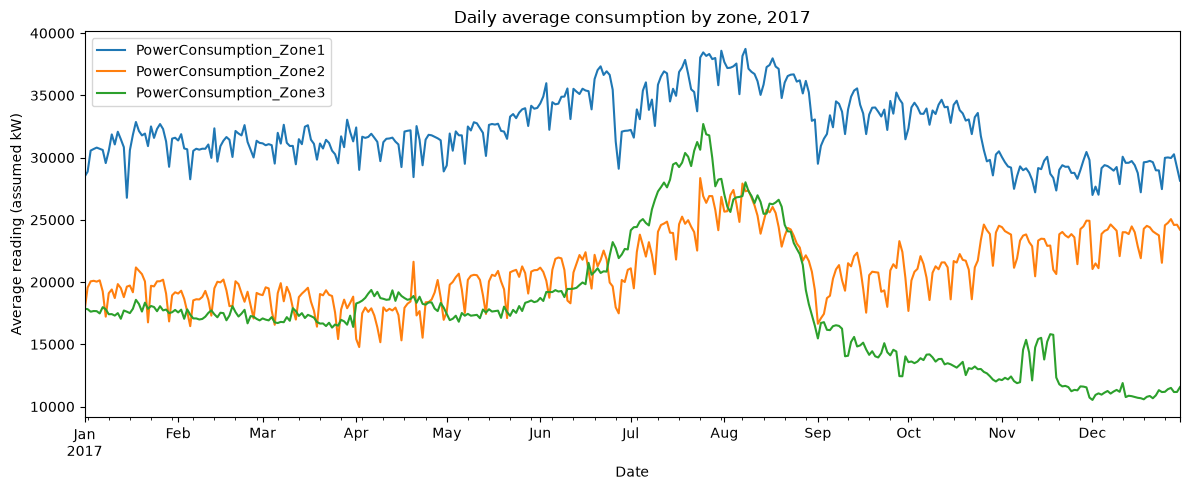

In [26]:
import os
os.makedirs("figures", exist_ok=True)
daily_zone = df.groupby("Date")[zones].mean()
daily_zone.index = pd.to_datetime(daily_zone.index)

fig, ax = plt.subplots(figsize=(12, 5))
daily_zone.plot(ax=ax)
ax.set_title("Daily average consumption by zone, 2017")
ax.set_xlabel("Date")
ax.set_ylabel("Average reading (assumed kW)")
plt.tight_layout()
plt.savefig("figures/01_daily_trend.png", dpi=150)
plt.show()

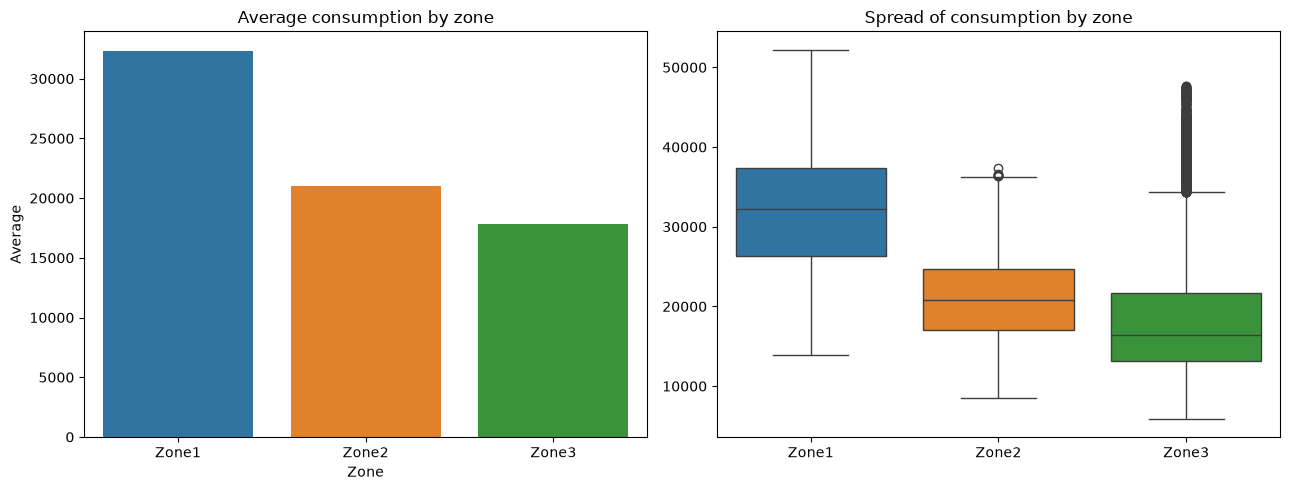

In [27]:
short = {z: z.replace("PowerConsumption_", "") for z in zones}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
avg = df[zones].mean().rename(index=short).reset_index()
avg.columns = ["Zone", "Average"]
sns.barplot(data=avg, x="Zone", y="Average", hue="Zone", legend=False, ax=axes[0])
axes[0].set_title("Average consumption by zone")
sns.boxplot(data=df[zones].rename(columns=short), ax=axes[1])
axes[1].set_title("Spread of consumption by zone")
plt.tight_layout()
plt.savefig("figures/02_zone_comparison.png", dpi=150)
plt.show()

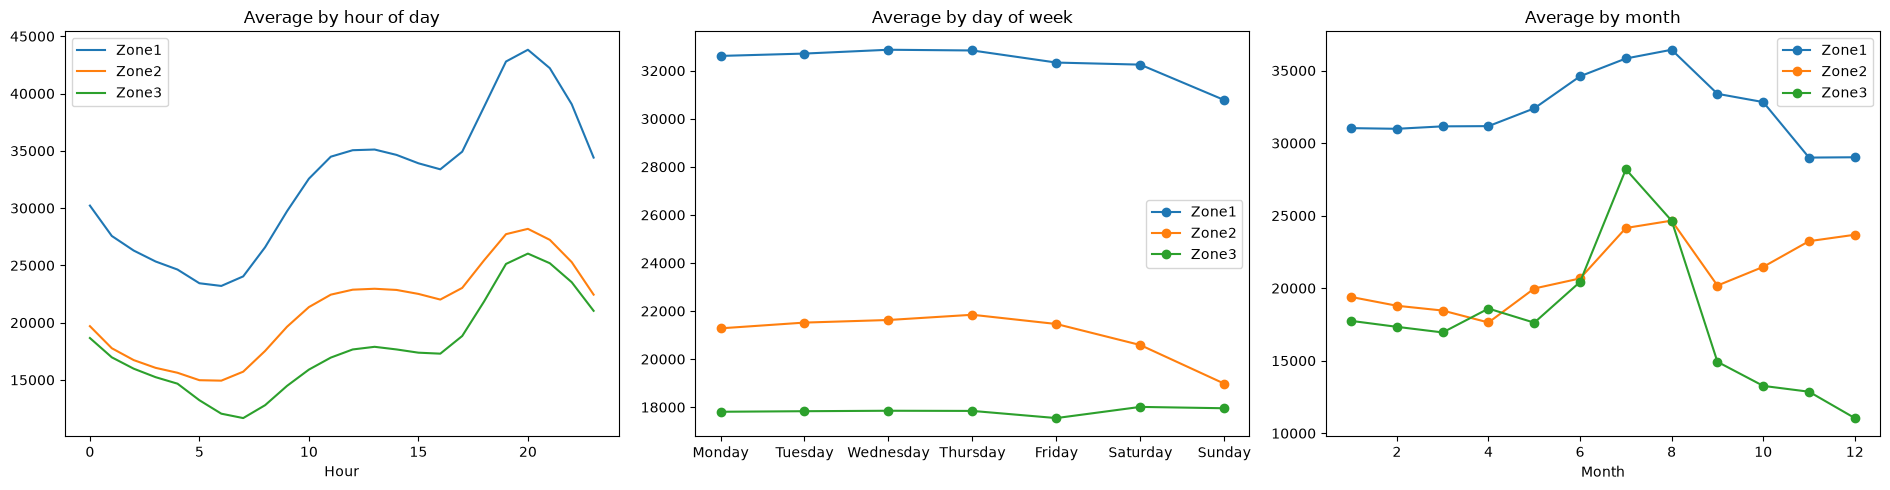

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5))
hourly.rename(columns=short).plot(ax=axes[0], title="Average by hour of day")
weekly.rename(columns=short).plot(ax=axes[1], marker="o", title="Average by day of week")
monthly.rename(columns=short).plot(ax=axes[2], marker="o", title="Average by month")
axes[0].set_xlabel("Hour"); axes[1].set_xlabel(""); axes[2].set_xlabel("Month")
plt.tight_layout()
plt.savefig("figures/03_hour_week_month.png", dpi=150)
plt.show()

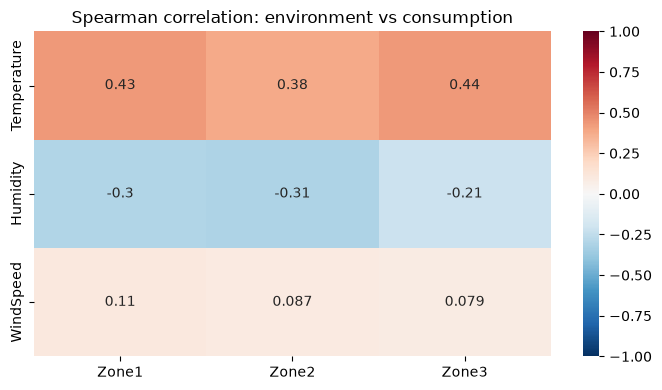

In [29]:
corr = df[env + zones].corr(method="spearman").loc[env, zones]
corr.columns = [short[c] for c in corr.columns]
plt.figure(figsize=(7, 4))
sns.heatmap(corr, annot=True, cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation: environment vs consumption")
plt.tight_layout()
plt.savefig("figures/04_correlation_heatmap.png", dpi=150)
plt.show()

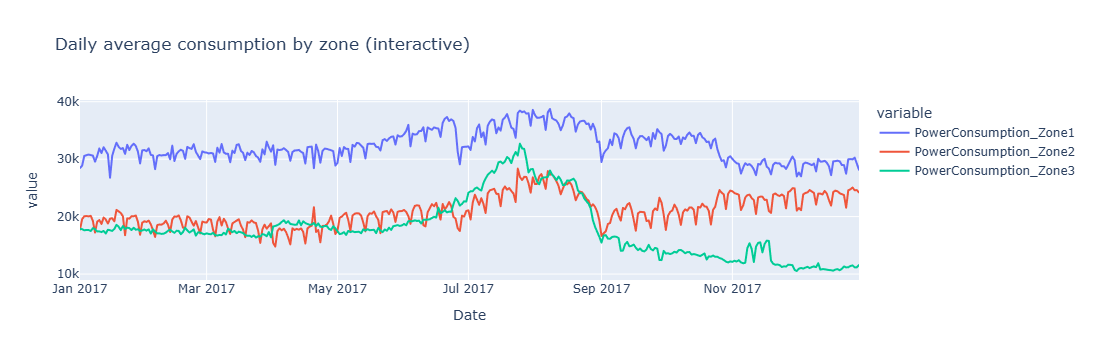

In [30]:
fig = px.line(daily_zone.reset_index(), x="Date", y=zones,
              title="Daily average consumption by zone (interactive)")
fig.write_html("figures/05_daily_trend_interactive.html")
fig.show()

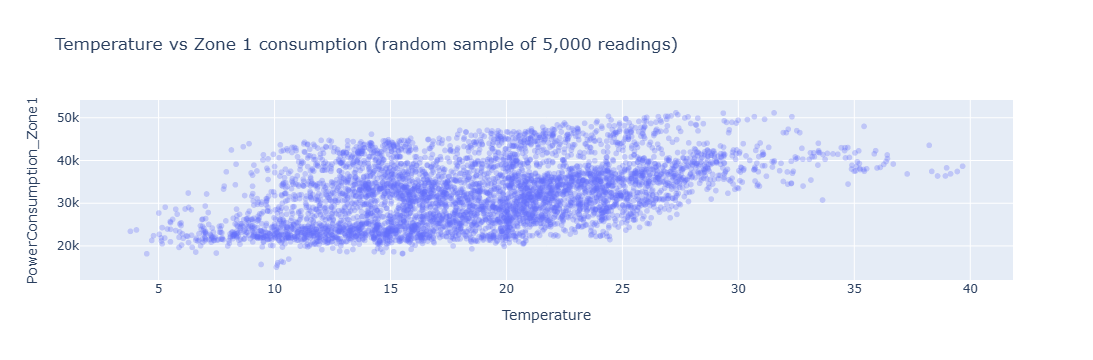

In [31]:
sample = df.sample(5000, random_state=1)
fig = px.scatter(sample, x="Temperature", y="PowerConsumption_Zone1", opacity=0.3,
                 title="Temperature vs Zone 1 consumption (random sample of 5,000 readings)")
fig.write_html("figures/06_temperature_scatter.html")
fig.show()

# Task 6: Business Insights and Recommendations

## Key findings
1. **Zone 1 uses the most; Zone 3 varies the most.** Zone 1 averages 32,345 (45.4% of the total), Zone 2 21,043 (29.5%), Zone 3 17,835 (25.0%). Zone 3's spread relative to its average is 0.371, against 0.220 for Zone 1.
2. **There is a strong daily cycle.** All zones peak at 20:00 and are lowest at 06:00 to 07:00. Zone 1 averages 43,823 at 20:00 against 23,204 at 06:00, about 89% higher.
3. **Summer is the high season.** July and August are the busiest months (Zone 1 peaks in August at 36,435; Zone 3 in July at 28,194). The highest all-zone reading was on 24 July at 20:10 (134,208, about 1.9 times the typical 71,223), and the busiest day was 25 July.
4. **Weekends are a little quieter, mainly in Zones 1 and 2.** Sunday is about 6% below the weekday average in Zone 1 and about 12% below in Zone 2. Zone 3 hardly changes across the week.
5. **Temperature is the most useful environmental indicator.** It has a moderate positive association with consumption in every zone (Spearman 0.38 to 0.44), and Zone 1 averages about 36,500 in the warmest quarter of readings against about 28,900 in the coolest. Humidity and wind speed are weak once the daily cycle is accounted for.
6. **Zone 3 falls sharply after August.** Its monthly average drops from 24,649 in August to 14,923 in September and 11,045 in December. The data does not show why.

## What this means for an energy management organisation
Demand is concentrated in the evening and in hot summer months, so capacity and planning pressure sits there, and Zone 3 behaves differently from the other two.

## Recommendations
1. **Target the 19:00 to 22:00 evening peak** with demand-management measures, such as time-based pricing or customer messaging, since all zones peak at 20:00.
2. **Prepare for July and August** by planning capacity and monitoring temperature forecasts as an early warning, especially for Zone 3, which rises most on hot days.
3. **Investigate the Zone 3 drop after August** with operational data (changes in customers, supply, or metering) before using its summer figures to plan next year.
4. **Schedule maintenance and low-risk work in the early-morning trough (04:00 to 07:00) and on Sundays,** when demand is lowest.
5. **Collect multi-year data** so seasonal patterns can be separated from one-off events.

## Limitations
One year only (1 Jan to 30 Dec 2017), so seasonality cannot be confirmed. The consumption unit is assumed to be power in kW, not kWh. Correlation is not causation, because temperature, season and time of day move together. The meaning of the diffuse flow columns is unclear.

In [32]:
clean = df.drop(columns=["TempBand", "AllZones"], errors="ignore")
clean.to_csv("powerconsumption_cleaned.csv", index=False)
print(clean.shape)

(52416, 16)
